In [9]:
%load_ext autoreload
%autoreload 2

# Static configuration

## Device

In [ ]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

first_layout_qubit = 43
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

## Lattice

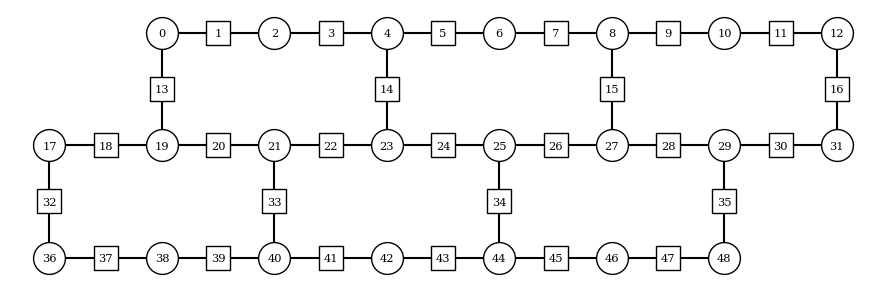

In [ ]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 2

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

## Options

In [ ]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

lattice_dims_arr = [(3, 2)]
J_arr = [5]
# g_arr = [0.01, 0.05, 0.1, 0.15, 0.2]
h_arr = [5]
lamb_arr = [1]
g_arr = [10]

x_basis = False

fractional_gates = False

# strings_arr = [[6, 7, 8, 16, 26, 25, 24, 34, 43, 44, 45, 54, 64, 63, 62, 72, 81, 82, 83, 92, 102, 101, 100]]
strings_arr = [[4, 14, 24, 34, 45, 53, 63]]
# strings_arr = [[12, 16, 30, 35, 47, 53, 64, 72, 81, 90, 98, 109, 115, 127, 131]]
# strings_arr = [[4, 14, 24]]

final_time = 2
dt = 0.1
steps = 35

max_layers = 50
adjust_depth = True

shots = 75000

odr = True
flip_threshold = 3

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

## Circuits

In [ ]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, dt, steps, backend, optimization_level, g, first_layout_qubit, x_basis, True, False)
        if odr:
            physical_circuits, this_odr_circuits = simulation_and_odr_circuits(*circs_args)
        else:
            physical_circuits = string_quench_simulation_circuits_dt(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {}))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits[0][0])

CircuitError: 'Index 53 out of range for size 49.'

## Hardware execution

In [ ]:
from utils.postselection import execute_postselected_sampler_batch
from itertools import product

jobs = [] # jobs[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_jobs = []
    for Ji, hi, lambi, gi in product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr))):
        params_ind = gi + lambi*len(g_arr) + hi*len(g_arr)*len(lamb_arr) + Ji*len(g_arr)*len(lamb_arr)*len(g_arr)
        if odr:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], odr_circuits=odr_circuits[i][params_ind], extra_options=extra_options[i][params_ind], job_db=job_db)
        else:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], extra_options=extra_options[i][params_ind], job_db=job_db)
        this_dims_jobs.append(this_jobs)
    jobs.append(this_dims_jobs)

## Load jobs

In [ ]:
from utils.postselection import load_postselected_jobs
from itertools import product

observables = [] # jobs[dims][Jhλg][t]
samples_dicts = [] # samples_dicts[dims][Jhλg][t]
postselected_samples_dicts = [] # postselected_samples_dicts[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_observables = []
    this_dims_samples_dicts = []
    this_dims_postselected_samples_dicts = []
    for j, (Ji, hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        clean_extra_options = extra_options[i][j].copy()
        if odr:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, odr_circuits=odr_circuits[i][j], max_shots=shots)
        else:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, max_shots=shots)
        this_dims_observables.append(this_observables)
        this_dims_samples_dicts.append(this_samples_dicts)
        this_dims_postselected_samples_dicts.append(this_postselected_samples_dicts)
    observables.append(this_dims_observables)
    samples_dicts.append(this_dims_samples_dicts)
    postselected_samples_dicts.append(this_dims_postselected_samples_dicts)

## Plot

In [ ]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

for i, (px, py) in enumerate(lattice_dims_arr):
    for j, (Ji, Hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        local_obs_anim((1 - observables[i][j][0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
        local_obs_anim((1 - observables[i][j][1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
        local_obs_anim((1 - observables[i][j][2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
        local_obs_anim((1 - observables[i][j][3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

# Reproducing 1D dynamics

## Device

In [1]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

## Lattice

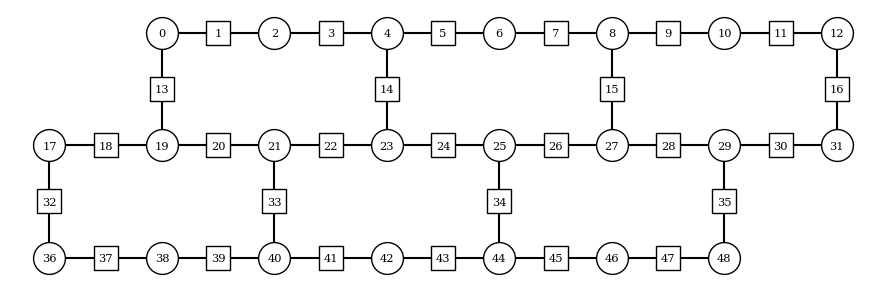

In [2]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

## Options

In [3]:
from z2hex.gdd import random, constant, counteract_rotation, from_matrix, zero_mean_gdd_matrix
from utils.hexec import ExecDB
from functools import partial
import numpy as np

lattice_dimensions = (3, 2)

J_1d = 5
J_rest = 25
h_1d = 0.8
h_rest = 25
lamb_1d = 1
lamb_rest = 0

fractional_gates = False

chain_qubits_on_lattice = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 16, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 32, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46])
particle_pair_left_position = len(chain_qubits_on_lattice)//4 - 3 
particle_pair_length = 6
string_arr = [chain_qubits_on_lattice[2*particle_pair_left_position]]
string_arr += chain_qubits_on_lattice[2*particle_pair_left_position + 1:2*particle_pair_left_position + 2*particle_pair_length + 1:2].tolist()
string_arr += [chain_qubits_on_lattice[2*particle_pair_left_position+2*particle_pair_length]]
string_arr = [int(qb) for qb in string_arr]

x_basis = False

final_time = 5
dt = 0.15
steps = 40
confidence = 0.7

shots = 300000

odr = True
postselect_odr = False
flip_threshold = 7
all_or_first_layout_qubit = 3
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = partial(from_matrix, matrix=zero_mean_gdd_matrix(lattice, steps))

if callable(g_func):
    g_func.__name__ = from_matrix.__name__


sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_sanity_checks.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

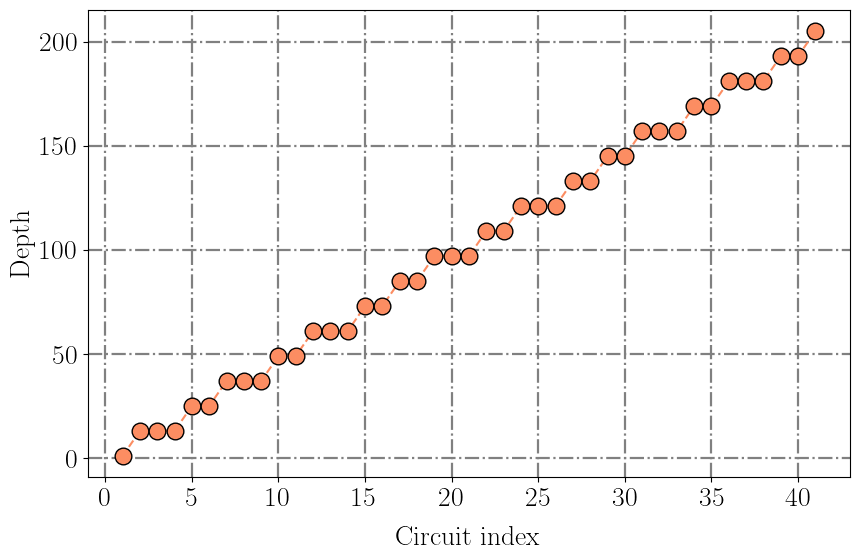

In [4]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

lattice = HeavyHexLattice(*lattice_dimensions)

layout_node_qinds = lattice.coords_to_logical_qb(lattice.node_coords)
layout_gauge_quinds = lattice.coords_to_logical_qb(lattice.edge_coords)

Js = np.full(len(lattice.node_coords), J_rest, dtype=float)
for qbind in chain_qubits_on_lattice[::2]:
    lind = np.where(np.equal(layout_node_qinds, qbind))[0]
    Js[lind] = J_1d
hs = np.full(len(lattice.edge_coords), h_rest, dtype=float)
lambdas = np.full(len(lattice.edge_coords), lamb_rest, dtype=float)
for qbind in chain_qubits_on_lattice[1::2]:
    lind = np.where(np.equal(layout_gauge_quinds, qbind))[0]
    hs[lind] = h_1d
    lambdas[lind] = lamb_1d

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]

optimization_level = 3

circs_args = (lattice, Js, hs, lambdas, string_arr, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, False)
if odr:
    circuits, odr_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dimensions[0], "plaquette_height": lattice_dimensions[1], "J": Js.tolist(), "h": hs.tolist(), "λ":lambdas.tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits[0])

In [7]:
from utils.postselection_multithreaded import execute_postselected_sampler_batch
from itertools import product

jobs = [] # jobs[t]

if odr:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, odr_circuits=odr_circuits, extra_options=extra_options, job_db=job_db)
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, job_db=job_db)

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:822: UserWarning: The backend ibm_marrakesh currently has a status of internal.
  warnings.warn(


## Load jobs

In [ ]:
from utils.postselection_multithreaded import load_postselected_jobs
from itertools import product

if odr:
    observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, postselect_odr=postselect_odr, verbose=True)
else:
    observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=True, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)

Loaded 328 jobs                                                                                    


## Plots

In [7]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

postselected_odr_filepath = f"z2hex_1drepro_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"z2hex_1drepro_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
odr_filepath = f"z2hex_1drepro_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
raw_filepath = f"z2hex_1drepro_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
local_obs_anim((1 - observables[0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
local_obs_anim((1 - observables[1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
local_obs_anim((1 - observables[2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
local_obs_anim((1 - observables[3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

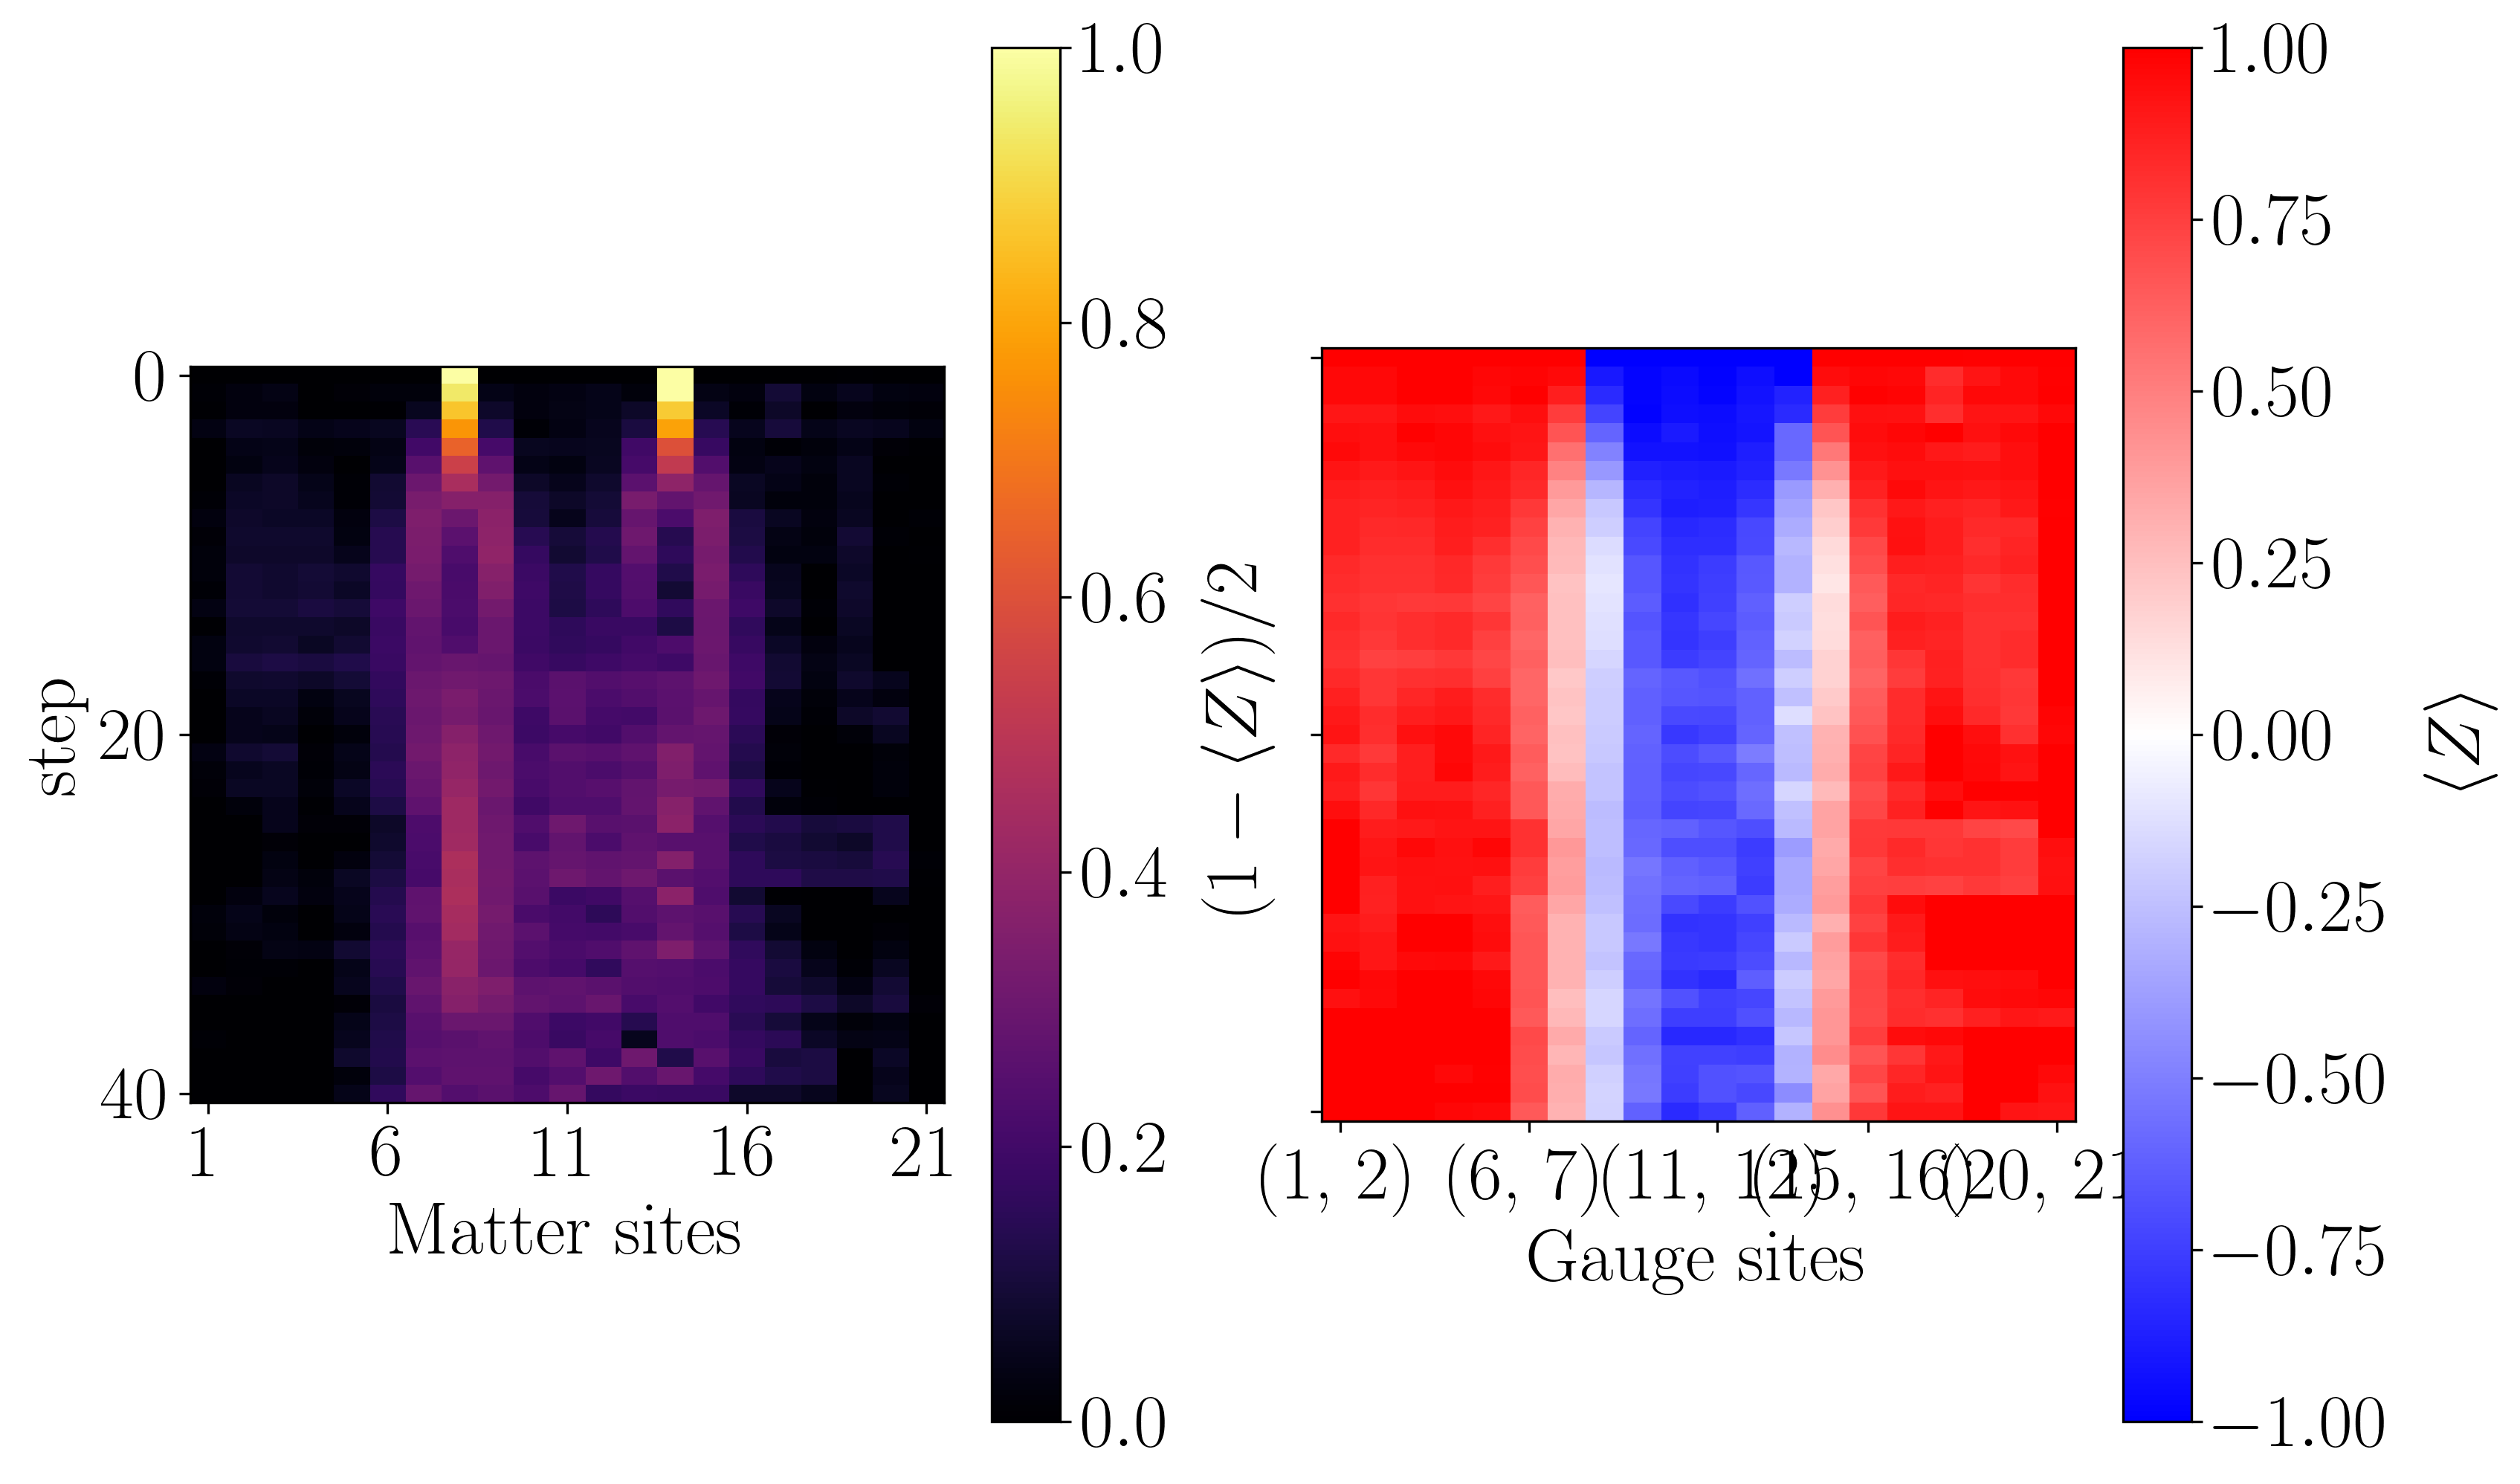

In [19]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observables[0][:, chain_qubits_on_lattice], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

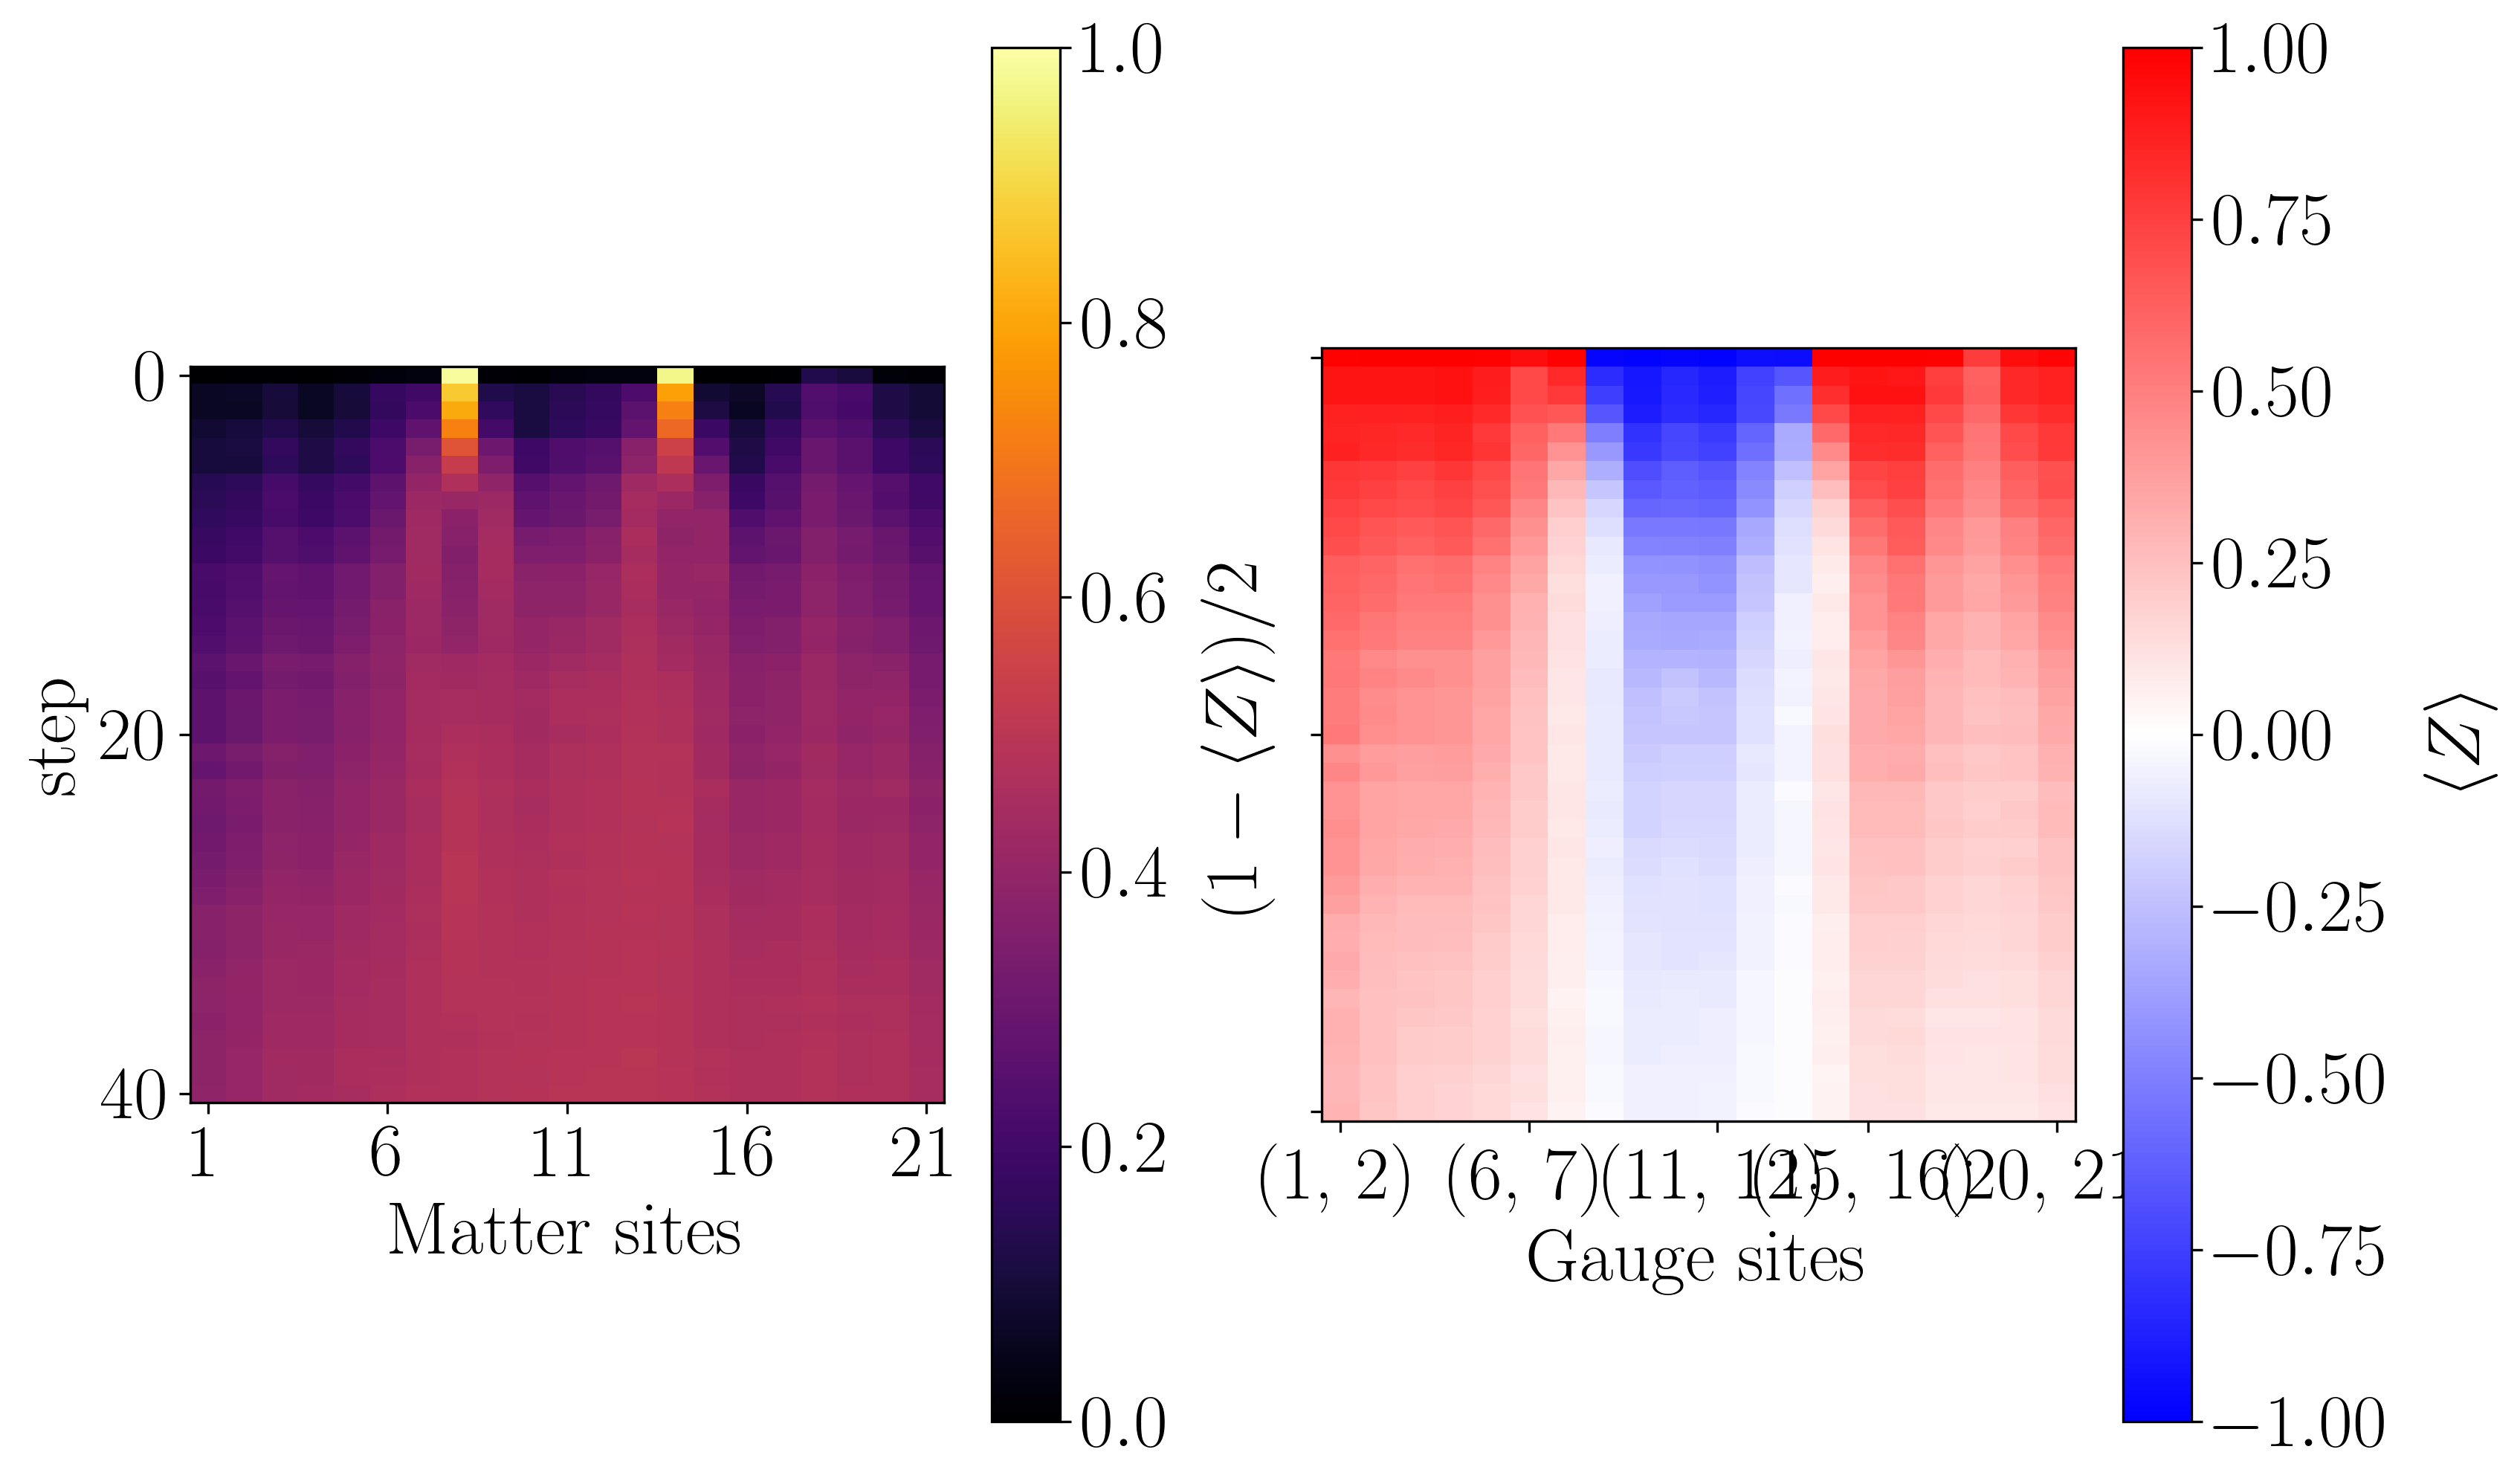

In [20]:
x_t_separated_plot(observables[1][:, chain_qubits_on_lattice], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

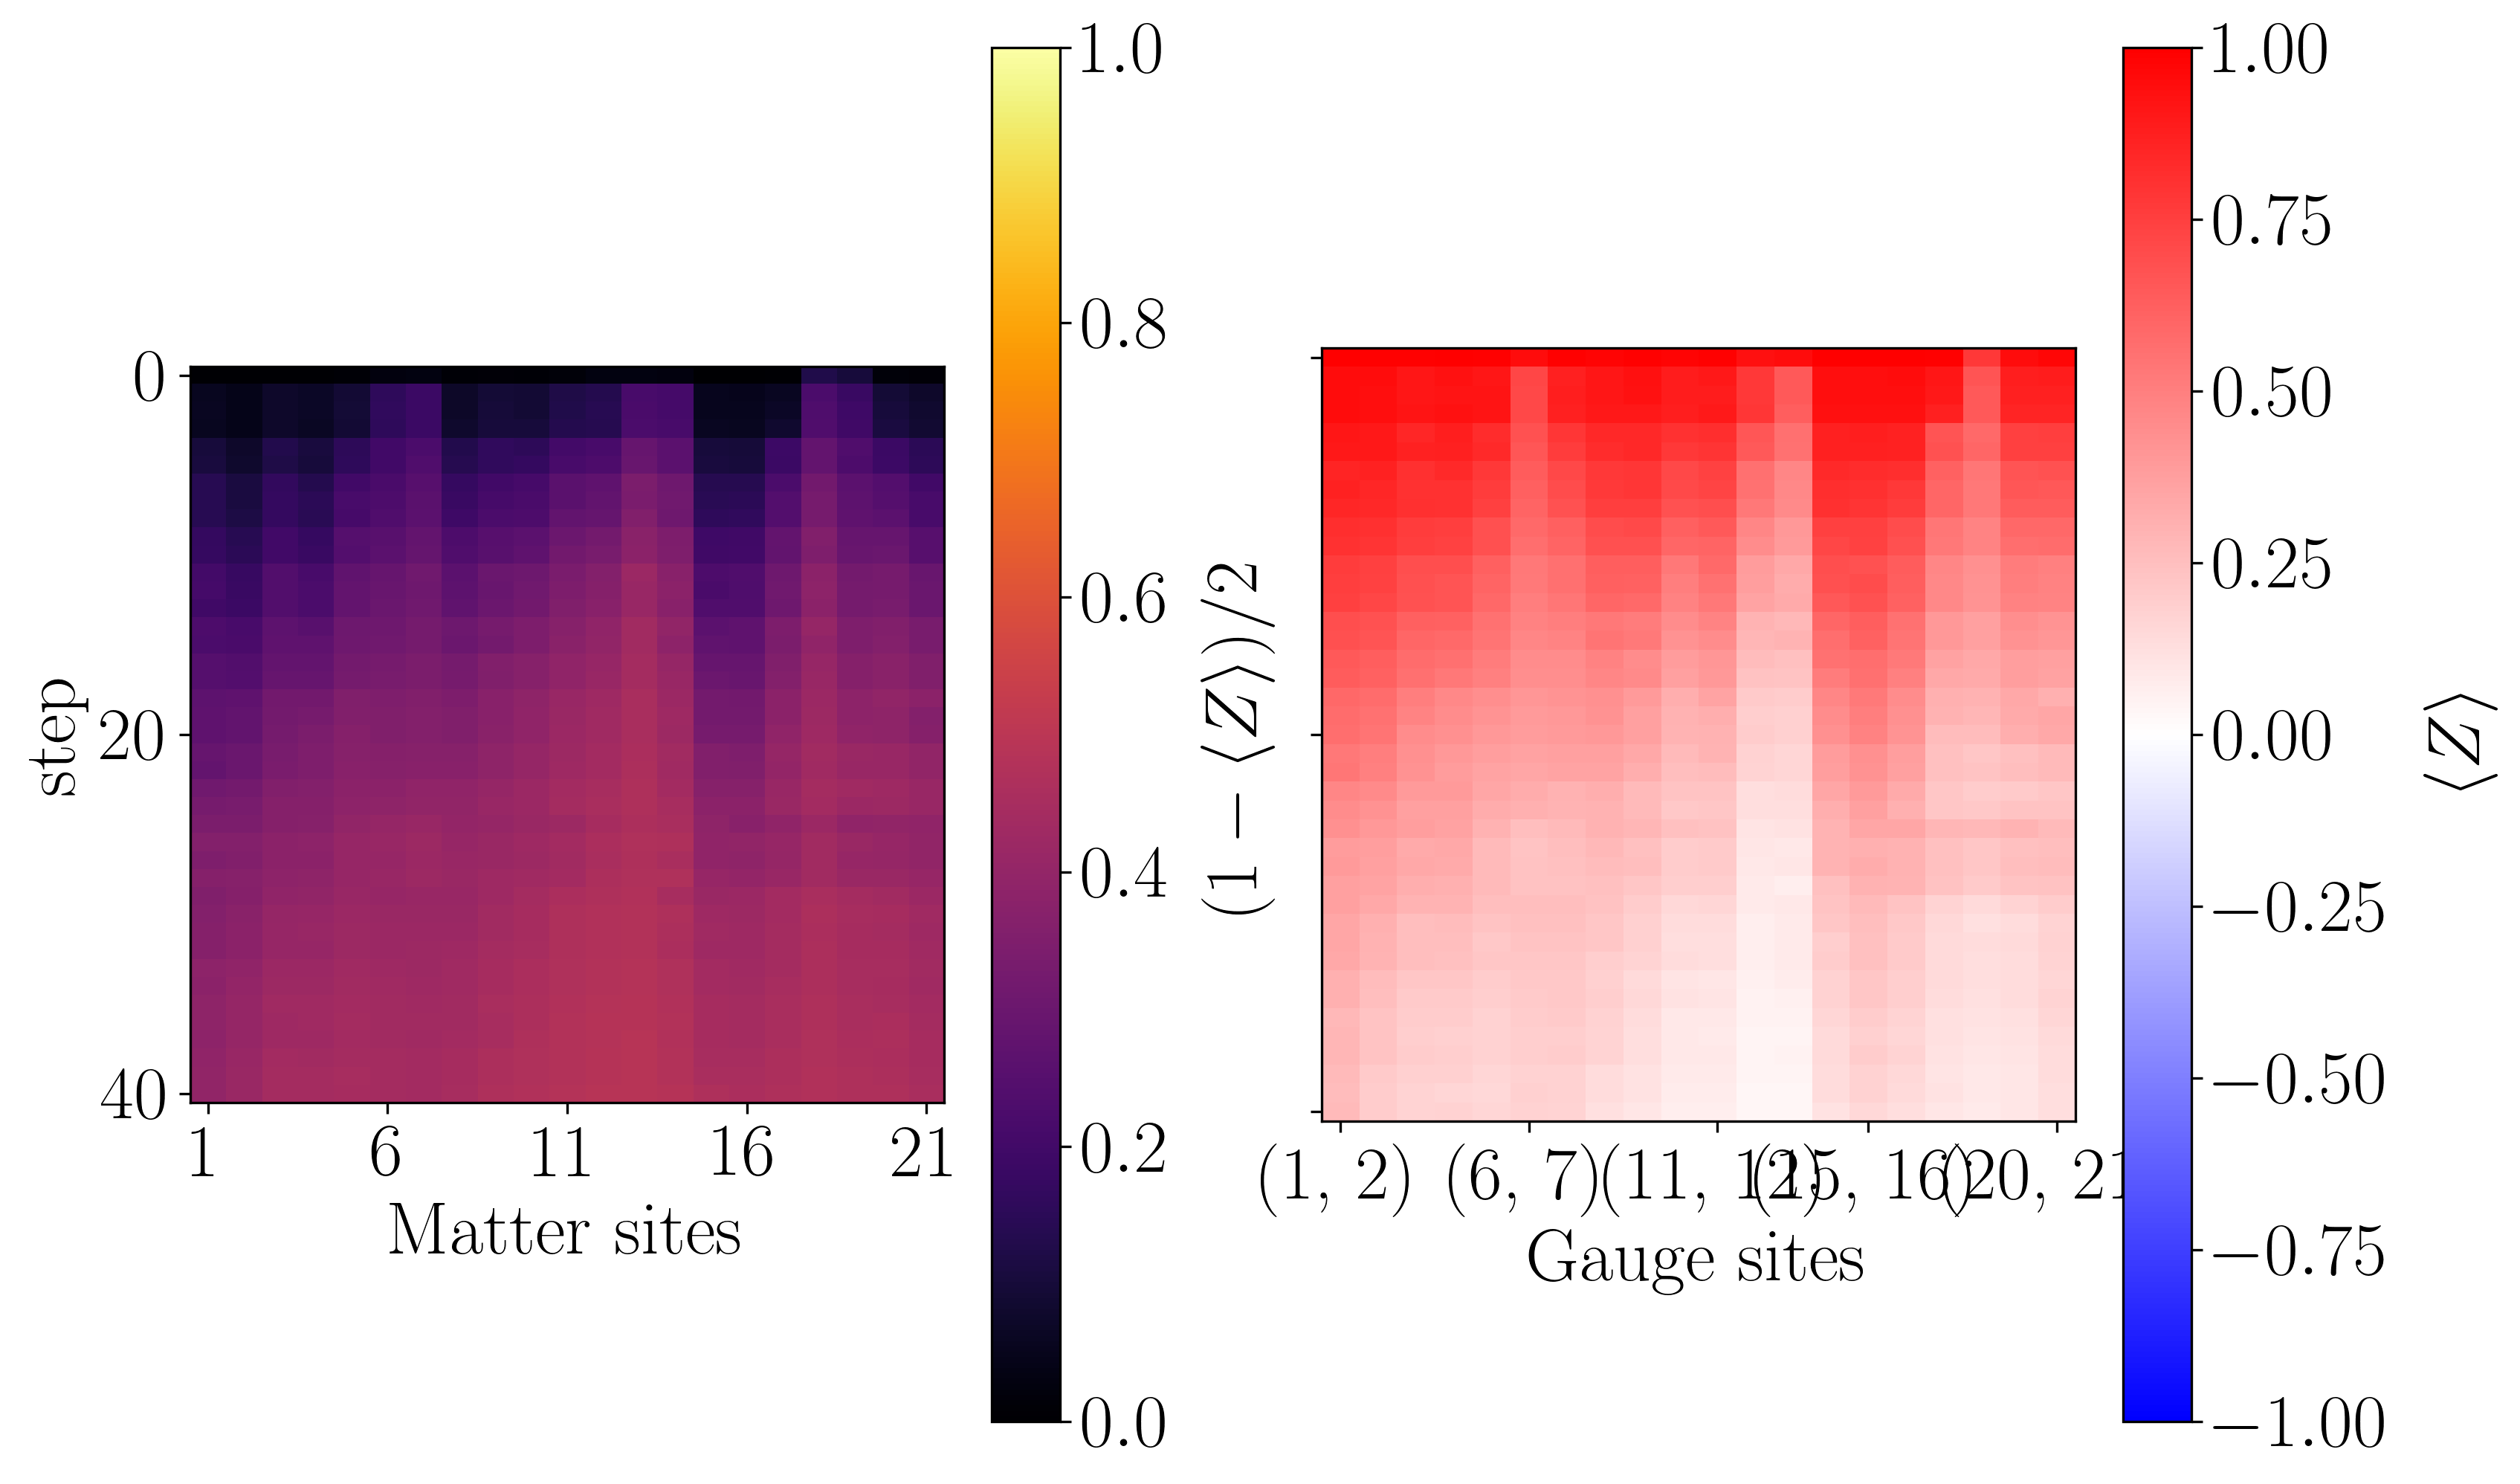

In [21]:
x_t_separated_plot(observables[2][:, chain_qubits_on_lattice], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

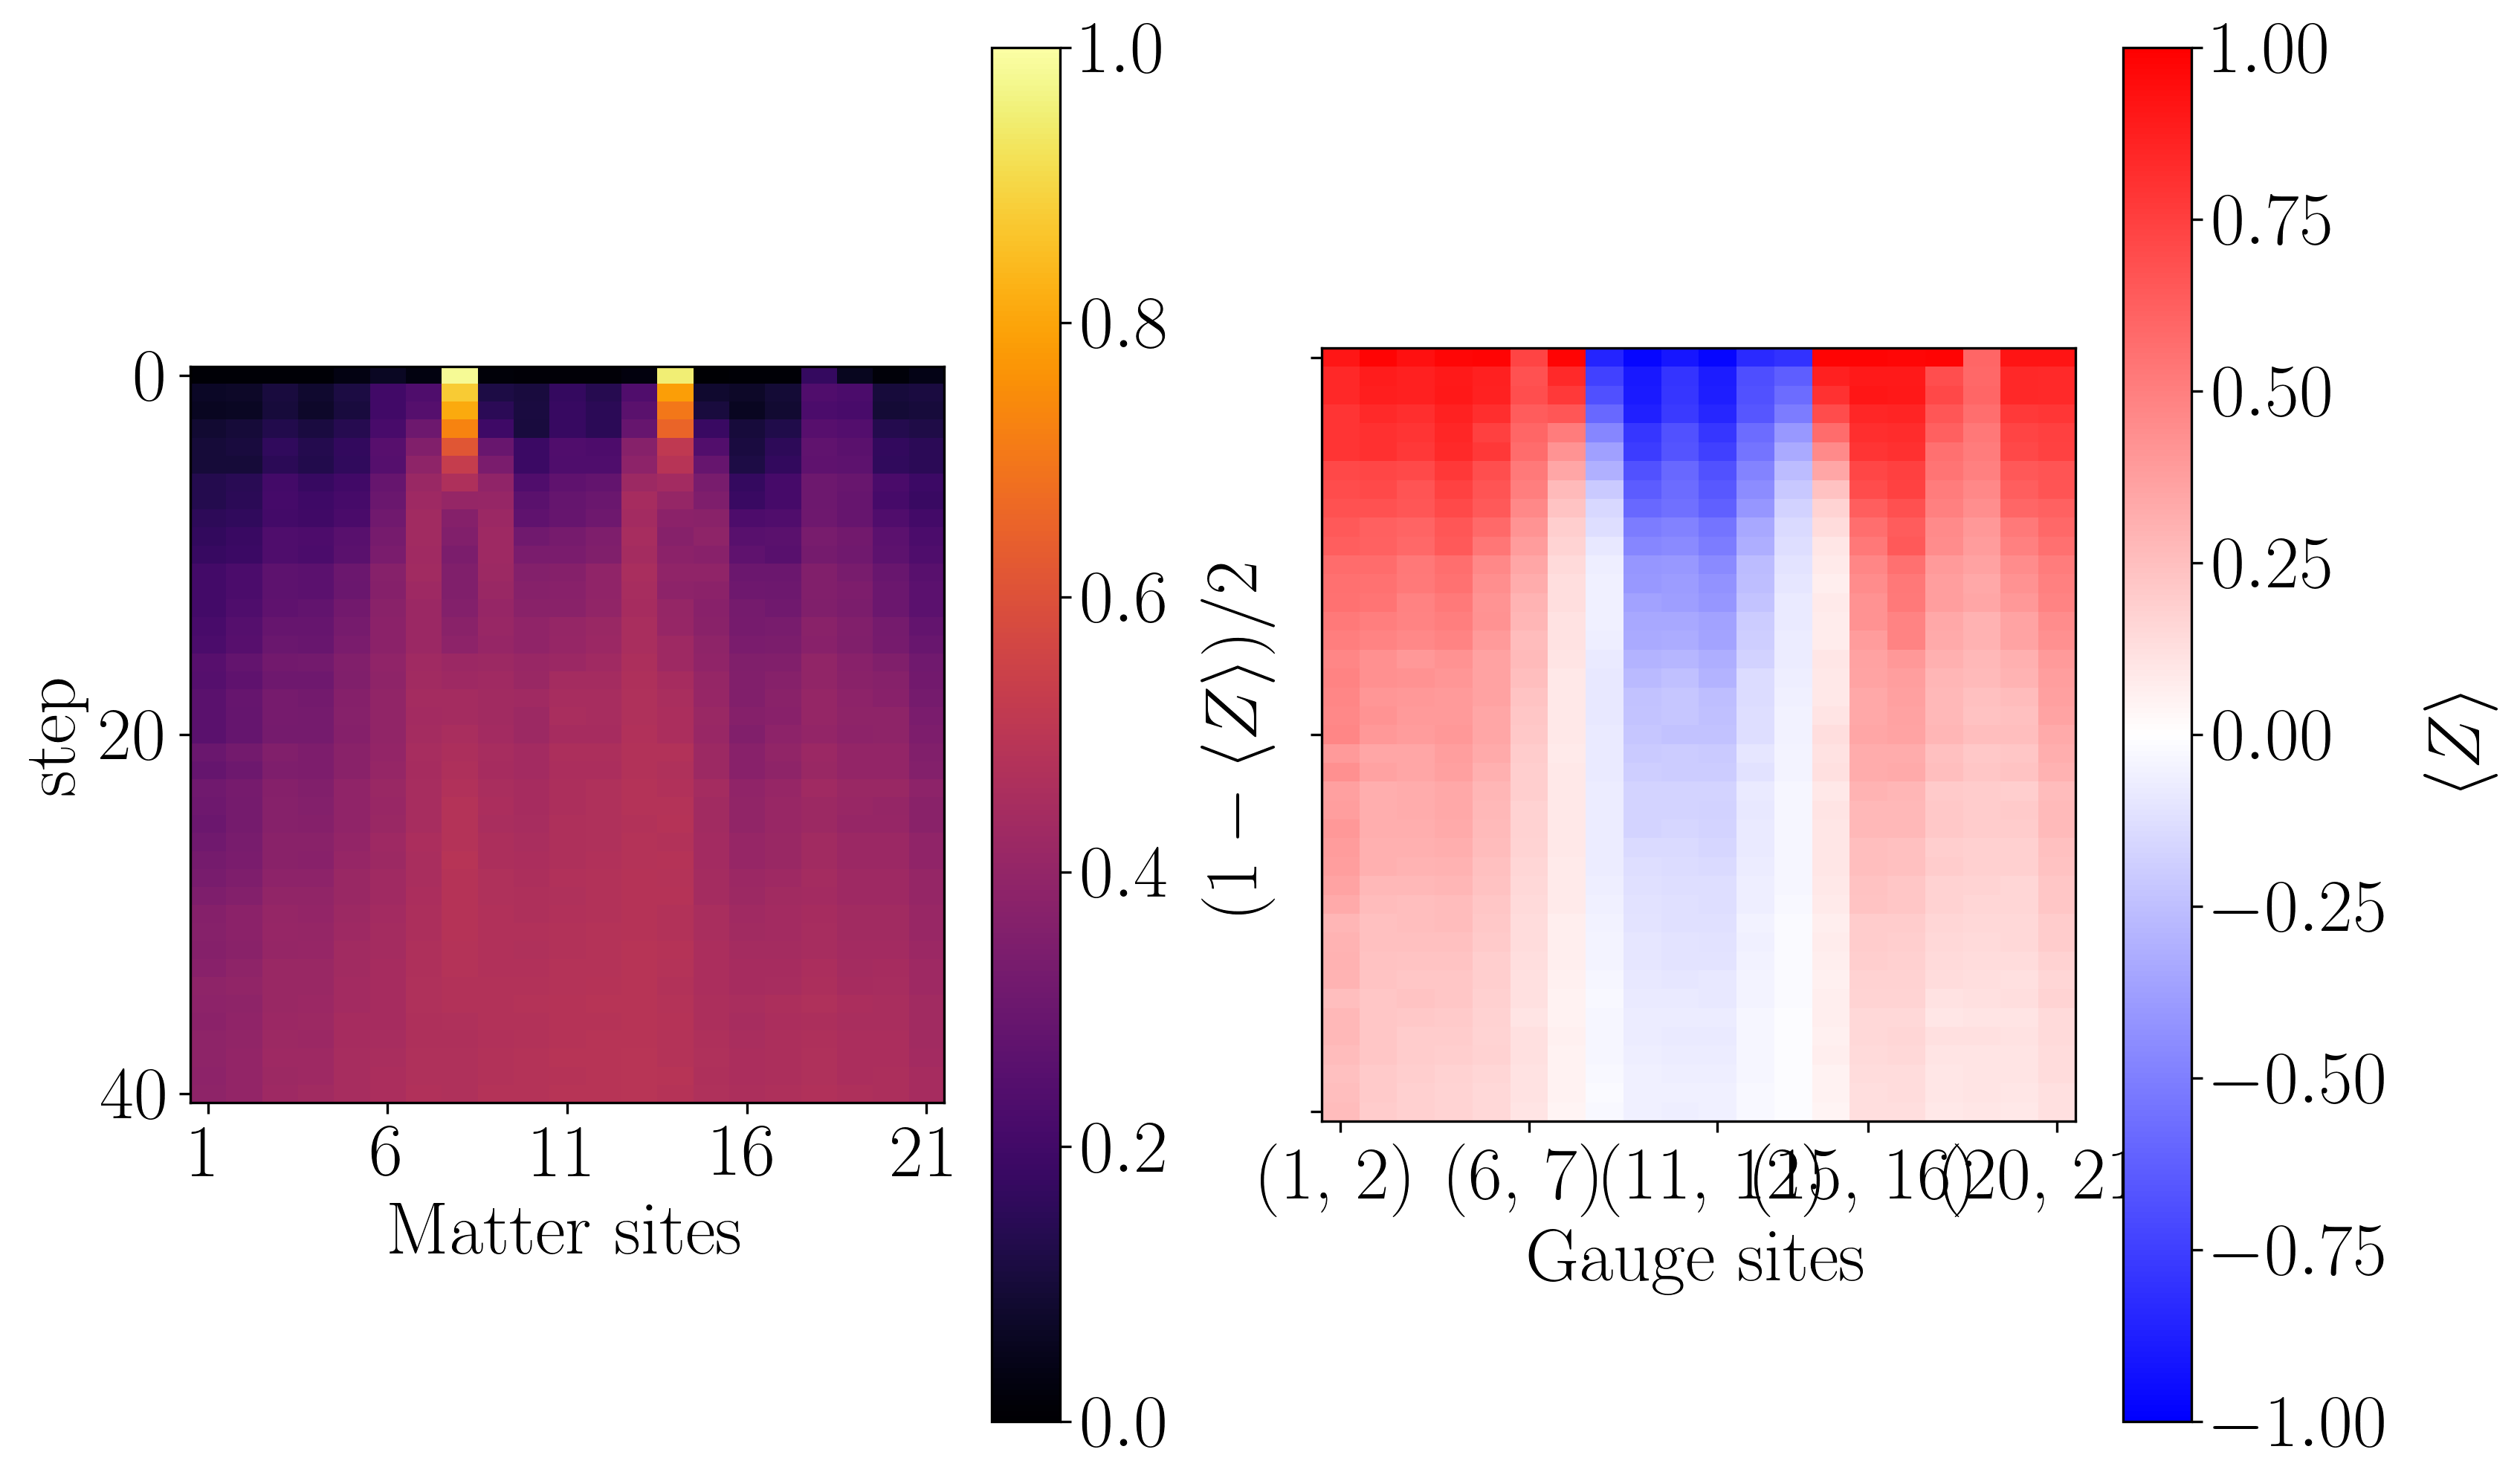

In [13]:
x_t_separated_plot(observables[3][:, chain_qubits_on_lattice], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

In [48]:
observables[0][:, ::2]

array([[1.00000672, 1.00022848, 0.99997982, ..., 0.99995982, 1.0001671 ,
        1.00006015],
       [1.01423338, 0.95593533, 0.96880321, ..., 0.96600259, 1.00113752,
        1.00823946],
       [1.05391482, 0.99221613, 0.97889009, ..., 0.99212425, 1.00359132,
        1.00979973],
       ...,
       [0.94983766, 0.95703751, 0.95405007, ..., 1.01201959, 0.94337142,
        0.80801489],
       [0.97477639, 0.96395071, 0.71899778, ..., 1.00682168, 0.93675139,
        0.83826931],
       [0.9748753 , 0.86133529, 0.92301741, ..., 1.00183959, 0.94191601,
        0.85295198]])

In [ ]:
import qiskit
import qiskit_ibm_runtime

In [52]:
qiskit.version.get_version_info()

'1.3.0'

In [54]:
import qiskit_ibm_runtime
qiskit_ibm_runtime.version.get_version_info()

'0.33.2'